# APM_50441_EP - Machine Learning 2 - Lab 1: Risk estimation, weights, hyperparameters and time series

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/APM-50441-EP/APM_50441_EP-2026-2027/blob/main/PC1/APM_50441_EP_Lab_1_simplified_with_solution.ipynb) or run it on your own computer (see *Working environment* below).

This lab illustrates the first lecture (*Setting, Risk Estimation... and Time Series*). Its goals are:
- to estimate the risk of a predictor and to measure the uncertainty of this estimation (hold-out, cross validation, comparison of two models, selection rules),
- to take into account a difference between the training and the real-world proportions, and a cost depending on the prediction (weights, Bayes rule),
- to compare hyperparameter search strategies with a fixed budget, and to see how much the selection itself can be overfitted,
- to validate a forecast correctly when the data are a time series.

We use `Python` with `scikit-learn`, `polars` and `seaborn`.

**Working environment.** Colab is the simplest option: open the notebook of this lab from the course repository (*Open in Colab* link) and run it. To work on your own computer, download the lab folder (the notebook and its files) or clone the course repository, and open the notebook in an IDE that runs Jupyter notebooks (VS Code with the Python and Jupyter extensions, JupyterLab, Spyder, PyCharm). Create a Python environment once with [`uv`](https://docs.astral.sh/uv/): `uv venv`, activate it (`source .venv/bin/activate`, or `.venv\Scripts\activate` on Windows) and `uv pip install jupyter`, or build the whole course environment with `uv sync` in `PC/env`; then select this environment as the kernel of the notebook. The installation cell below installs the packages of the lab into the Python running the notebook (Colab or your environment), and the data are read from the local files when they are present (otherwise they are downloaded).

**Use of AI.** AI assistants (e.g. the ones built into Colab or VS Code) are allowed, but you must be able to explain every line you use, and you should answer the *predict before you run* questions before running the code: the suggested code may not be correct!

All the libraries of the core part are installed at once. On Colab, restart the session once after this installation; locally, restart the kernel if the installation upgraded a package that was already loaded.

In [2]:
# Installs into the Python running this notebook: Colab, or locally an activated virtual environment
import sys
!uv pip install --python "{sys.executable}" "scikit-learn==1.9.1" "polars==1.44.2" "seaborn==0.13.2" "fairlearn==0.14.0" "optuna==5.0.0" "statsmodels==0.15.0"

Using Python 3.12.14 environment at: ~\.venvs\apm50441
Checked 6 packages in 59ms


We use the Credit Risk dataset prepared by IBM (a biased version of the classical German credit data), and `apm_credit.py`, a small module gathering the cost model that we build step by step in this lab, so that the next labs can simply import it. Each file is downloaded only if there is no local copy.

In [3]:
import os
import urllib.request

# each file is downloaded only if there is no local copy
CSV_URL = "https://raw.githubusercontent.com/IBM/monitor-wml-model-with-watson-openscale/master/data/german_credit_data_biased_training.csv"
APM_CREDIT_URL = "https://raw.githubusercontent.com/APM-50441-EP/APM_50441_EP-2026-2027/main/common/apm_credit.py"  # course repository
for url in [CSV_URL, APM_CREDIT_URL]:
  filename = url.split('/')[-1]
  if not os.path.exists(filename):
    urllib.request.urlretrieve(url, filename)

The dataset, the training/test split and two pipelines (a logistic regression and a nearest neighbors classifier) are given: this was the content of the first labs of the previous course.

In [4]:
import numpy as np
import polars as pl
import polars.selectors as cs
import seaborn.objects as so
import matplotlib.pyplot as plt

import sklearn
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from threadpoolctl import threadpool_limits
threadpool_limits(limits=2, user_api='openmp')  # on such small datasets, many threads are slower than a few (Colab has 2 cores)

german_credit = pl.read_csv("german_credit_data_biased_training.csv")
X = german_credit.drop('Risk')
y = german_credit['Risk']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

categorical_features = X.select(cs.string()).columns
numerical_features = X.select(cs.numeric()).columns
preprocessor = ColumnTransformer(transformers=[
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features),
    ('num', StandardScaler(), numerical_features)])

def make_pipeline(classifier):
  return Pipeline(steps=[('preprocessor', clone(preprocessor)), ('classifier', classifier)]).set_output(transform="polars")

pipeline_log = make_pipeline(LogisticRegression(max_iter=1000))
pipeline_nn = make_pipeline(KNeighborsClassifier(n_neighbors=15))
german_credit.shape, y_train.value_counts(normalize=True).sort('Risk')

((5000, 21),
 shape: (2, 2)
 ┌─────────┬────────────┐
 │ Risk    ┆ proportion │
 │ ---     ┆ ---        │
 │ str     ┆ f64        │
 ╞═════════╪════════════╡
 │ No Risk ┆ 0.666      │
 │ Risk    ┆ 0.334      │
 └─────────┴────────────┘)

## 1. Risk estimation and model comparison

The *risk* of a predictor $f$ is its average loss on a new observation, $\mathcal{R}(f) = \mathbb{E}[\ell(Y, f(X))]$. It is unknown and must be estimated from data that have not been used to train $f$.

**Question** *Predict before you run.* For the $1$-nearest neighbor, the $15$-nearest neighbors and the logistic regression, what do you expect for the accuracy on the training set compared with the accuracy on the test set? Check it.

**Answer**

In [5]:
results = []
for name, pipeline in {'1-NN': make_pipeline(KNeighborsClassifier(n_neighbors=1)),
                       '15-NN': pipeline_nn, 'logistic': pipeline_log}.items():
  pipeline.fit(X_train, y_train)
  results.append({'model': name, 'training accuracy': pipeline.score(X_train, y_train),
                  'test accuracy': pipeline.score(X_test, y_test)})
pl.DataFrame(results).with_columns((pl.col('training accuracy') - pl.col('test accuracy')).alias('optimism'))

model,training accuracy,test accuracy,optimism
str,f64,f64,f64
"""1-NN""",1.0,0.739,0.261
"""15-NN""",0.8095,0.798,0.0115
"""logistic""",0.80275,0.8,0.00275


**Conclusion** The $1$-NN has a training accuracy of $1$ (each point is its own nearest neighbor) but a test accuracy of $0.739$: an optimism of $0.26$. The optimism is much smaller for the $15$-NN ($0.012$) and the logistic regression ($0.003$), which are less flexible. The training error is an optimistic estimate of the risk (PC1, Exercise 1), all the more so as the method can adapt to the training data.

---

A single test set gives a single, noisy, estimate. To see how noisy, we can repeat the *hold-out* procedure: split the training set into a training part and a validation part many times.

**Question** Estimate the accuracy of the logistic regression with $20$ random hold-out splits ($80\%$/$20\%$) of the training set, and with a $5$-fold cross validation repeated $4$ times (`StratifiedKFold(n_splits=5, shuffle=True, random_state=i)`). Compare the spread of the individual estimates, and of the averages.

**Answer**

In [6]:
from sklearn.model_selection import ShuffleSplit
holdout = cross_val_score(pipeline_log, X_train, y_train, cv=ShuffleSplit(n_splits=20, test_size=0.2, random_state=0))
cv_repeated = pl.concat([pl.DataFrame({'rep': i, 'fold': range(5),
                                       'score': cross_val_score(pipeline_log, X_train, y_train,
                                                                cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=i))})
                         for i in range(4)])
print(f'hold-out: mean {holdout.mean():.4f}, sd {holdout.std(ddof=1):.4f}')
cv_repeated.group_by('rep').agg(pl.col('score').mean().alias('mean'), pl.col('score').std().alias('sd')).sort('rep')

hold-out: mean 0.7966, sd 0.0098


rep,mean,sd
i32,f64,f64
0,0.79625,0.017744
1,0.79725,0.005184
2,0.79725,0.010947
3,0.79775,0.016593


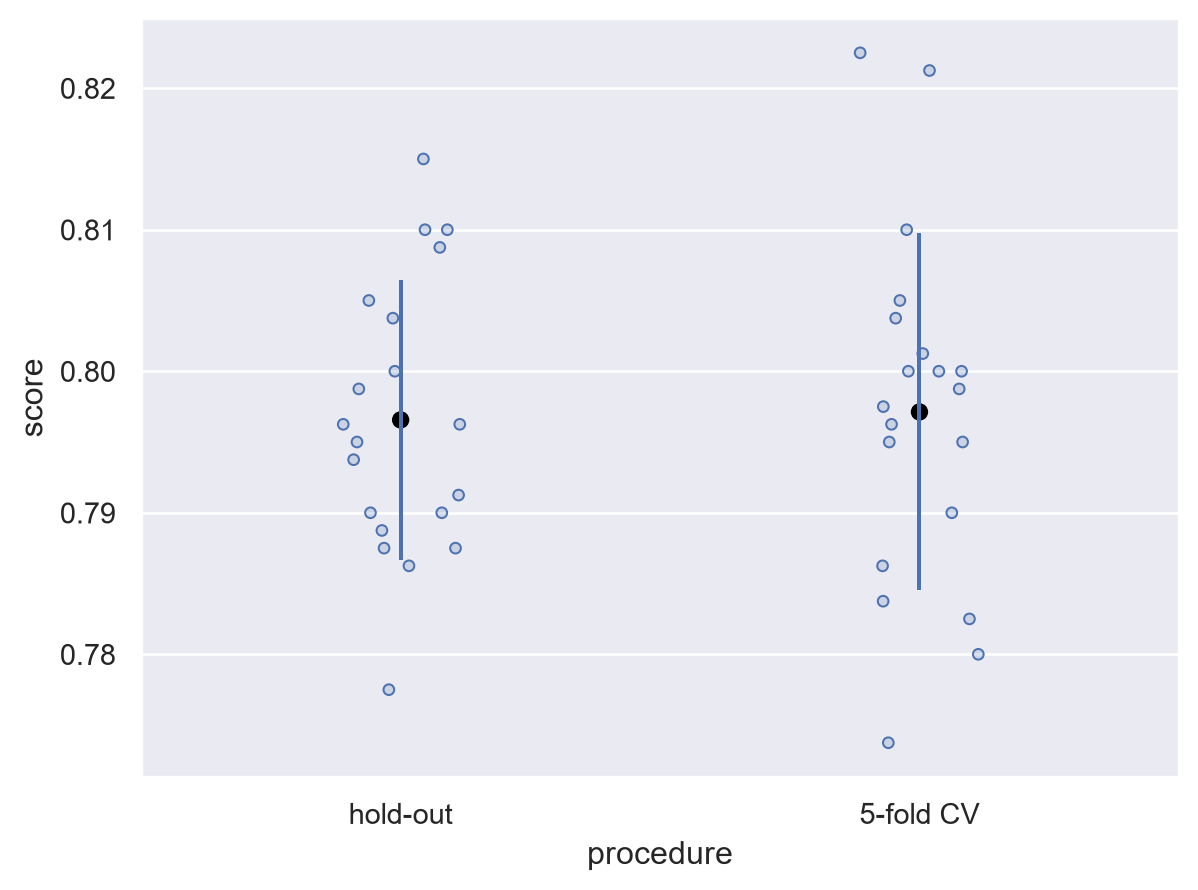

In [7]:
(so.Plot(pl.concat([pl.DataFrame({'procedure': 'hold-out', 'score': holdout}),
                    cv_repeated.select(pl.lit('5-fold CV').alias('procedure'), 'score')]), x='procedure', y='score')
 .add(so.Dots(), so.Jitter(.3))
 .add(so.Range(), so.Est(errorbar='sd'))
 .add(so.Dot(color='black'), so.Agg()))

**Conclusion** The $20$ hold-out estimates have a standard deviation of about $0.010$: a single hold-out split could give anything between about $0.78$ and $0.81$. The fold scores of the cross validation are as variable (standard deviations from $0.005$ to $0.018$ depending on the shuffle), but their averages are much more stable: from $0.796$ to $0.798$ for the $4$ repetitions. Averaging over the folds, and over repetitions, reduces the variance of the estimate.

---

The standard deviation of the fold scores describes the variability of the accuracy of *one* fitted model on *one* validation set; the standard error (the standard deviation divided by $\sqrt{V}$) describes the variability of their *mean*, under an independence assumption that does not hold (the training parts of the folds overlap).

**Question** Compare the logistic regression and the $15$-nearest neighbors on the *same* folds ($5$-fold CV repeated $4$ times). Compute the paired differences, and compare a naive $t$-test, which assumes independent differences, with the *corrected resampled $t$-test* of Nadeau and Bengio, which inflates the variance of the mean difference from $s^2/J$ to $(1/J + n_{\text{val}}/n_{\text{train}})\, s^2$.

**Answer**

In [8]:
from scipy import stats
differences = []
for i in range(4):
  cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=i)
  differences.append(cross_val_score(pipeline_log, X_train, y_train, cv=cv) - cross_val_score(pipeline_nn, X_train, y_train, cv=cv))
d = np.concatenate(differences)
J = len(d)
t_naive = d.mean() / np.sqrt(d.var(ddof=1) / J)
t_corrected = d.mean() / np.sqrt((1 / J + 1 / 4) * d.var(ddof=1))
pl.DataFrame({'test': ['naive t-test', 'corrected resampled t-test'], 'mean difference': [d.mean()] * 2,
              't': [t_naive, t_corrected],
              'p-value': [2 * stats.t.sf(abs(t_naive), J - 1), 2 * stats.t.sf(abs(t_corrected), J - 1)]})

test,mean difference,t,p-value
str,f64,f64,f64
"""naive t-test""",0.010938,3.720569,0.00145
"""corrected resampled t-test""",0.010938,1.518916,0.145249


**Conclusion** The logistic regression is better on average by $0.011$. The naive $t$-test finds this very significant ($p = 0.001$), but the differences are not independent: the folds share most of their training data and the repetitions reuse the same observations. The corrected resampled $t$-test inflates the variance accordingly and gives $p = 0.15$: the difference is not significant. Comparisons of cross-validated scores must take the dependence into account (and remain approximate: no unbiased estimator of the variance of a cross validation exists).

---

**Question** Choose the number of neighbors $k$ among the values below with a $5$-fold cross validation, with three rules: the best average accuracy, the simplest model (largest $k$) whose average is within one standard error of the best one (*one standard error rule*), and the best *worst fold* (a pessimistic, quantile-based rule in the spirit of the PAC approach of the lecture). Evaluate the selected models once on the test set.

In [9]:
n_neighbors_values = [1, 3, 5, 9, 15, 25, 41, 67, 111, 181, 301]

**Answer**

In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
k_scores = pl.concat([pl.DataFrame({'k': k, 'fold': range(5),
                                    'score': cross_val_score(make_pipeline(KNeighborsClassifier(n_neighbors=k)),
                                                             X_train, y_train, cv=cv, n_jobs=2)})
                      for k in n_neighbors_values])
summary = (k_scores.group_by('k').agg(pl.col('score').mean().alias('mean'), pl.col('score').std().alias('sd'),
                                      pl.col('score').min().alias('worst fold'))
           .with_columns((pl.col('sd') / np.sqrt(5)).alias('se')).sort('k'))
best = summary.filter(pl.col('mean') == pl.col('mean').max()).row(0, named=True)
rules = {'best mean': best['k'],
         'one standard error': summary.filter(pl.col('mean') >= best['mean'] - best['se'])['k'].max(),
         'best worst fold': summary.filter(pl.col('worst fold') == pl.col('worst fold').max())['k'].max()}
print(rules)
pl.DataFrame([{'rule': rule, 'k': k,
               'CV accuracy': summary.filter(pl.col('k') == k)['mean'][0],
               'test accuracy': make_pipeline(KNeighborsClassifier(n_neighbors=k)).fit(X_train, y_train).score(X_test, y_test)}
              for rule, k in rules.items()])

{'best mean': 41, 'one standard error': 181, 'best worst fold': 41}


rule,k,CV accuracy,test accuracy
str,i64,f64,f64
"""best mean""",41,0.794,0.801
"""one standard error""",181,0.792,0.795
"""best worst fold""",41,0.794,0.801


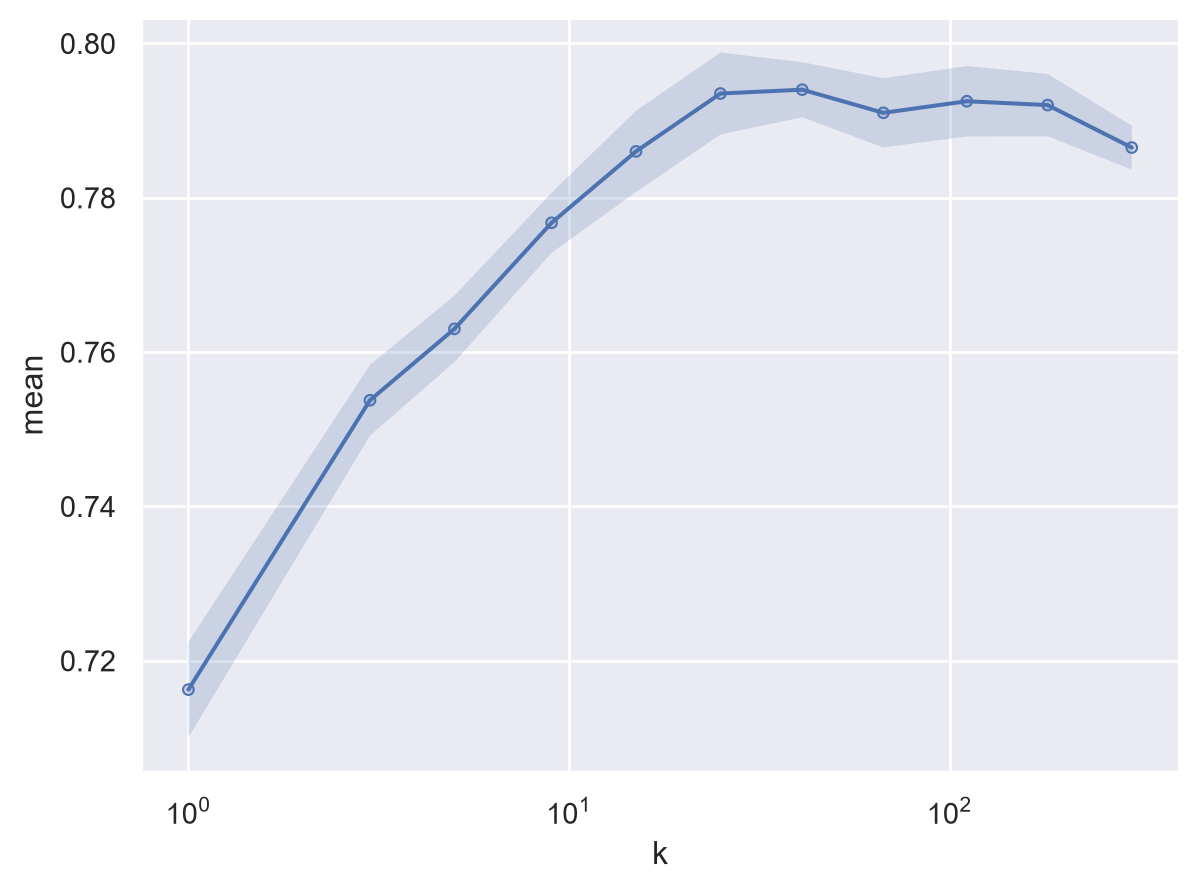

In [11]:
(so.Plot(summary, x='k', y='mean')
 .add(so.Line()).add(so.Dots())
 .add(so.Band(), ymin=summary['mean'] - summary['se'], ymax=summary['mean'] + summary['se'])
 .scale(x='log'))

**Conclusion** The best average accuracy ($0.794$) is obtained for $k = 41$, which also has the best worst fold. The one standard error rule selects a much simpler model, $k = 181$ (CV accuracy $0.792$, within one standard error of the best). On the test set, the three choices give $0.801$, $0.795$ and $0.801$: all the values of $k$ between about $25$ and $181$ have similar observed accuracies. The one-standard-error rule is a simplicity heuristic, and the rule mainly decides between simplicity and a (small, possibly illusory) gain. Note that the CV accuracy of the selected model is optimistic, as it is the maximum of $11$ noisy estimates (see the nested cross validation in *To go further*).

---

## 2. Unbalanced data, weights and costs

In our dataset, about one third of the loans are `Risk`, whereas we assume that in the real world the proportion of `Risk` is $\pi_{\text{Risk}} = 0.02$. If the conditional law of $X$ given $Y$ is the same in both worlds, an expectation in the real world is a *weighted* expectation in the training world, with a weight $w_y = \pi_y / \pi^{\text{train}}_y$ depending only on the class:
$$\mathbb{E}_{\text{real}}[\ell(Y, f(X))] = \mathbb{E}_{\text{train}}[w_Y\, \ell(Y, f(X))].$$

In [12]:
real_prop = {'Risk': .02, 'No Risk': .98}
train_prop = dict(y_train.value_counts(normalize=True).iter_rows())
custom_weight = {c: real_prop[c] / train_prop[c] for c in real_prop}
train_prop, custom_weight

({'Risk': 0.334, 'No Risk': 0.666},
 {'Risk': 0.059880239520958084, 'No Risk': 1.4714714714714714})

**Question** Write a function `custom_metric(y_true, y_pred)` computing the real-world accuracy (the weighted accuracy) and the corresponding scorer. What is the real-world accuracy of the logistic regression? Of a classifier that always predicts `No Risk`?

**Answer**

In [13]:
def compute_weights(y_true):
  return custom_weight['Risk'] * (y_true == 'Risk') + custom_weight['No Risk'] * (y_true == 'No Risk')

def custom_metric(y_true, y_pred):
  return 1 - (compute_weights(y_true) * (pl.Series(y_pred) != y_true)).mean()

custom_scorer = sklearn.metrics.make_scorer(custom_metric)
pipeline_log.fit(X_train, y_train)
{'logistic regression': custom_scorer(pipeline_log, X_test, y_test),
 'always No Risk': custom_metric(y_test, np.full(len(y_test), 'No Risk'))}

{'logistic regression': 0.8821546096995199, 'always No Risk': 0.98}

**Conclusion** The real-world accuracy of the logistic regression is only $0.88$, while a classifier that always predicts `No Risk` reaches $0.98$, the proportion of good loans in the real world. A classifier trained (and thresholded) for the proportions of the training set is badly suited to the real world.

---

Two ways of adapting the predictor are seen in the lecture: training with the weights (*weighted loss*), or keeping the probabilities estimated in the training world and changing the decision (*plug-in Bayes rule*): predict `Risk` when $w_{\text{Risk}}\, \hat{p}(\text{Risk}|x) > w_{\text{No Risk}}\, \hat{p}(\text{No Risk}|x)$.

To send weights to a step of a pipeline, `scikit-learn` uses *metadata routing*: each step declares whether it uses them.

**Question** Train the logistic regression with the weights (only the classifier should use them), and implement the plug-in decision. Compare their real-world accuracy on the test set.

**Answer** Once the routing is enabled, every step that *could* use the weights must say whether it does: here the scaler does not, the classifier does.

In [14]:
sklearn.set_config(enable_metadata_routing=True)

def make_weighted_pipeline(classifier):
  preprocessor_weighted = ColumnTransformer(transformers=[
      ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features),
      ('num', StandardScaler().set_fit_request(sample_weight=False), numerical_features)])
  return Pipeline(steps=[('preprocessor', preprocessor_weighted),
                         ('classifier', classifier.set_fit_request(sample_weight=True))]).set_output(transform="polars")

pipeline_log_weighted = make_weighted_pipeline(LogisticRegression(max_iter=1000))
pipeline_log_weighted.fit(X_train, y_train, sample_weight=compute_weights(y_train))

def custom_predict(pipeline, X):
  proba = pipeline.predict_proba(X)  # columns in the order of pipeline.classes_
  risk = list(pipeline.classes_).index('Risk')
  decision = custom_weight['Risk'] * proba[:, risk] > custom_weight['No Risk'] * proba[:, 1 - risk]
  return pl.Series(np.where(decision, 'Risk', 'No Risk'))

{'weighted training': custom_scorer(pipeline_log_weighted, X_test, y_test),
 'plug-in decision': custom_metric(y_test, custom_predict(pipeline_log, X_test))}

{'weighted training': 0.9816167664670659,
 'plug-in decision': 0.9807784431137725}

**Conclusion** Both adaptations reach a real-world accuracy of $0.98$ ($0.982$ for the weighted training, $0.981$ for the plug-in decision), i.e. the level of the trivial classifier: with these proportions, almost all the loans are predicted `No Risk`. The two sample accuracies are close. The population risk identity permits different finite-sample fits, especially with regularization or model misspecification. The accuracy is not the right criterion for this problem.

---

The accuracy is not the right criterion here: the cost of an error depends on the error and on the amount of the loan. We use the following cost model (the opposite of a gain):
- $5 + 0.6 \times \text{LoanAmount}$ if we grant a loan that defaults (`Risk` predicted `No Risk`),
- $1 - 0.05 \times \text{LoanAmount}$ if we grant a good loan (`No Risk` predicted `No Risk`): a benefit of $0.05 \times \text{LoanAmount}$ after a fixed cost of $1$,
- $1$ if we refuse the loan.

The cost model, the weighted cost metric and the corresponding scorers are gathered in `apm_credit.py`. The scorers return the *gain* (the opposite of the cost), and need `LoanAmount` as metadata:

In [15]:
import apm_credit
from apm_credit import cost_metric, cost_scorer, cost_scorer_from_proba, compute_cost_weights, compute_costs
apm_credit.set_proportions(y_train, real_prop)
LoanAmount_train, LoanAmount_test = X_train['LoanAmount'], X_test['LoanAmount']
cost_scorer(pipeline_log.fit(X_train, y_train), X_test, y_test, LoanAmount=LoanAmount_test)

83.58840527953103

**Question** *Predict before you run.* Write the Bayes rule for this cost: for a loan of amount $a$ and an estimated probability $p$ of `Risk`, when should we refuse it? Compute the threshold on $p$ for a loan of $5000$, and compare it with the threshold $1/2$ of `predict`.

**Answer** We refuse the loan when the expected (weighted) cost of granting it is larger than the expected cost of refusing it:
$$w_{\text{Risk}}\, p\, (5 + 0.6 a) + w_{\text{No Risk}}\, (1-p)\, (1 - 0.05 a) > w_{\text{Risk}}\, p + w_{\text{No Risk}}\, (1 - p),$$
i.e. when $p > \tau(a) = \dfrac{w_{\text{No Risk}}\, (0.05 a)}{w_{\text{No Risk}}\, (0.05 a) + w_{\text{Risk}}\, (4 + 0.6 a)}$.

In [16]:
def bayes_threshold(a):
  regret_refuse = custom_weight['No Risk'] * 0.05 * a        # cost of refusing a good loan, minus the one of granting it
  regret_grant = custom_weight['Risk'] * (4 + 0.6 * a)       # cost of granting a defaulting loan, minus the one of refusing it
  return regret_refuse / (regret_refuse + regret_grant)
bayes_threshold(5000)

0.6716004362325112

**Conclusion** For a loan of $5000$, the Bayes rule refuses the loan when the estimated probability of `Risk` is above $0.672$, much more than the threshold $1/2$ of `predict`: as defaults are rare in the real world, a loan is refused only when the model is quite sure. As shown in PC1, this threshold hardly depends on the amount (it tends to $0.672$ for large amounts).

---

**Question** Compare, with a $5$-fold cross validation of the gain on the training set, the original logistic regression, the logistic regression trained with the cost weights `compute_cost_weights(y, LoanAmount)`, the Bayes decision on the probabilities of the original one (`cost_scorer_from_proba`), and a threshold tuned by cross validation (`TunedThresholdClassifierCV`). Which one would you choose? Evaluate it on the test set.

**Answer**

In [17]:
from sklearn.model_selection import TunedThresholdClassifierCV
pipeline_log_cost_weighted = make_weighted_pipeline(LogisticRegression(max_iter=1000))
pipeline_tuned = TunedThresholdClassifierCV(clone(pipeline_log), scoring=cost_scorer, cv=5)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
cv_gains = pl.DataFrame({
  'original': cross_val_score(pipeline_log, X_train, y_train, cv=cv, scoring=cost_scorer,
                              params={'LoanAmount': LoanAmount_train}),
  'cost weighted': cross_val_score(pipeline_log_cost_weighted, X_train, y_train, cv=cv, scoring=cost_scorer,
                                   params={'LoanAmount': LoanAmount_train,
                                           'sample_weight': compute_cost_weights(y_train, LoanAmount_train)}),
  'Bayes decision': cross_val_score(pipeline_log, X_train, y_train, cv=cv, scoring=cost_scorer_from_proba,
                                    params={'LoanAmount': LoanAmount_train}),
  'tuned threshold': cross_val_score(pipeline_tuned, X_train, y_train, cv=cv, scoring=cost_scorer,
                                     params={'LoanAmount': LoanAmount_train})})
cv_gains.mean()

original,cost weighted,Bayes decision,tuned threshold
f64,f64,f64,f64
86.501282,96.346994,96.070744,96.270647


In [18]:
pipeline_log.fit(X_train, y_train)
cost_scorer_from_proba(pipeline_log, X_test, y_test, LoanAmount=LoanAmount_test)

94.47660392728059

**Conclusion** The original logistic regression has a CV gain of $86.5$. Taking the proportions and the costs into account improves it by about $10$ points, and the three approaches give similar observed gains: $96.3$ for the cost-weighted training, $96.1$ for the Bayes decision and $96.3$ for the tuned threshold (their differences are much smaller than the fold-to-fold variability). We choose the Bayes decision, which needs no extra training and adapts immediately if the costs or the proportions change. Its test gain is $94.5$, lower than its CV estimate but within the variability of a single test set.

---

## 3. Hyperparameter optimization with a fixed budget

We now tune a `HistGradientBoostingClassifier` (a model of Lecture 3, fast to train) for the cost-based gain of the Bayes decision. The lecture presents several strategies: an exhaustive grid, random search, *successive halving* (many candidates evaluated on small budgets, the best ones promoted to larger budgets), and Bayesian optimization (here Optuna's Tree-structured Parzen Estimator, TPE). We are going to compare them with roughly the same budget of $20$ full $3$-fold cross validations.

Note: `HistGradientBoostingClassifier` already uses several cores (we limited them to $2$ at the beginning of the lab); running several cross validations in parallel (`n_jobs`) on top of it oversubscribes them and is often *slower*, so we keep `n_jobs=None` here.

In [19]:
import time
import optuna
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.experimental import enable_halving_search_cv  # noqa: F401 (successive halving is still experimental)
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, HalvingRandomSearchCV
from scipy.stats import loguniform, randint

pipeline_hgb = make_pipeline(HistGradientBoostingClassifier(random_state=0))
cv3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=0)
grid = {'classifier__learning_rate': [0.01, 0.05, 0.2, 1.0], 'classifier__max_leaf_nodes': [3, 7, 15, 31, 63]}
distributions = {'classifier__learning_rate': loguniform(0.01, 1), 'classifier__max_leaf_nodes': randint(3, 64)}

~\.venvs\apm50441\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


**Question** Run a grid search on the $4 \times 5$ grid `grid`, a random search with $20$ draws from `distributions`, a successive halving search (`HalvingRandomSearchCV` with $60$ candidates, `factor=3` and `min_resources='exhaust'`, the resource being the number of training samples) and an Optuna study with $20$ trials of a TPE sampler, all with the gain of the Bayes decision (`cost_scorer_from_proba`) as score. Compare their best CV gains, their running times, and the gains of the selected models on the test set.

**Answer** The searches of `scikit-learn` route `LoanAmount` to the scorer; with Optuna, we write the objective ourselves.

In [20]:
searches, timings = {}, {}
for name, search in {
    'grid': GridSearchCV(pipeline_hgb, grid, cv=cv3, scoring=cost_scorer_from_proba),
    'random': RandomizedSearchCV(pipeline_hgb, distributions, n_iter=20, cv=cv3, scoring=cost_scorer_from_proba,
                                 random_state=0),
    'successive halving': HalvingRandomSearchCV(pipeline_hgb, distributions, n_candidates=60, factor=3,
                                                min_resources='exhaust', cv=cv3, scoring=cost_scorer_from_proba,
                                                random_state=0)}.items():
  start = time.perf_counter()
  searches[name] = search.fit(X_train, y_train, LoanAmount=LoanAmount_train)
  timings[name] = time.perf_counter() - start

In [21]:
def objective(trial):
  params = {'classifier__learning_rate': trial.suggest_float('learning_rate', 0.01, 1, log=True),
            'classifier__max_leaf_nodes': trial.suggest_int('max_leaf_nodes', 3, 63)}
  return cross_val_score(clone(pipeline_hgb).set_params(**params), X_train, y_train, cv=cv3,
                         scoring=cost_scorer_from_proba, params={'LoanAmount': LoanAmount_train}).mean()

optuna.logging.set_verbosity(optuna.logging.WARNING)
start = time.perf_counter()
study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=0))
study.optimize(objective, n_trials=20)
timings['TPE (Optuna)'] = time.perf_counter() - start
best_tpe = clone(pipeline_hgb).set_params(classifier__learning_rate=study.best_params['learning_rate'],
                                          classifier__max_leaf_nodes=study.best_params['max_leaf_nodes']).fit(X_train, y_train)

In [22]:
best_models = {name: search.best_estimator_ for name, search in searches.items()} | {'TPE (Optuna)': best_tpe}
best_cv = {name: search.best_score_ for name, search in searches.items()} | {'TPE (Optuna)': study.best_value}
pl.DataFrame([{'search': name, 'time (s)': timings[name], 'best CV gain': best_cv[name],
               'test gain': cost_scorer_from_proba(model, X_test, y_test, LoanAmount=LoanAmount_test)}
              for name, model in best_models.items()])

search,time (s),best CV gain,test gain
str,f64,f64,f64
"""grid""",37.309092,96.193296,97.441249
"""random""",55.388762,96.168754,95.656648
"""successive halving""",80.443999,93.471173,95.26634
"""TPE (Optuna)""",56.642823,96.16606,96.386566


**Conclusion** With the same budget, the grid search, the random search and the TPE reach the same best CV gain ($96.2$); the successive halving only reaches $93.5$: its first rounds evaluate the $60$ candidates on very few loans, where the cost-based gain (driven by a few large defaults) is very noisy, and good candidates are eliminated early. Successive halving pays off when the ranking on small budgets is reliable, which is not the case here. Their running times are of the same order (from about $40$ to $80$ s here; the timings depend on the machine and its load). The test gains vary more ($95.3$ to $97.4$) than the CV gains, and their ranking differs: the differences between the searches are within the noise of a single test set. With two hyperparameters and this budget, all the strategies work; the advantage of random search and TPE over a grid appears with more hyperparameters, few of which really matter (Bergstra and Bengio).

---

To measure sensitivity to the fold assignment, select the best configuration using shuffle A and score it using shuffle B of the same 400 loans. Both shuffles reuse all observations.

**Question** Draw $60$ random configurations from `distributions`. For each of them, compute the $3$-fold CV gain on the small training set with two different shuffles (A and B). As a function of the number $m$ of configurations tried, plot the best CV gain on A (the reported one) and the CV gain on B of the configuration selected on A. Comment.

**Answer**

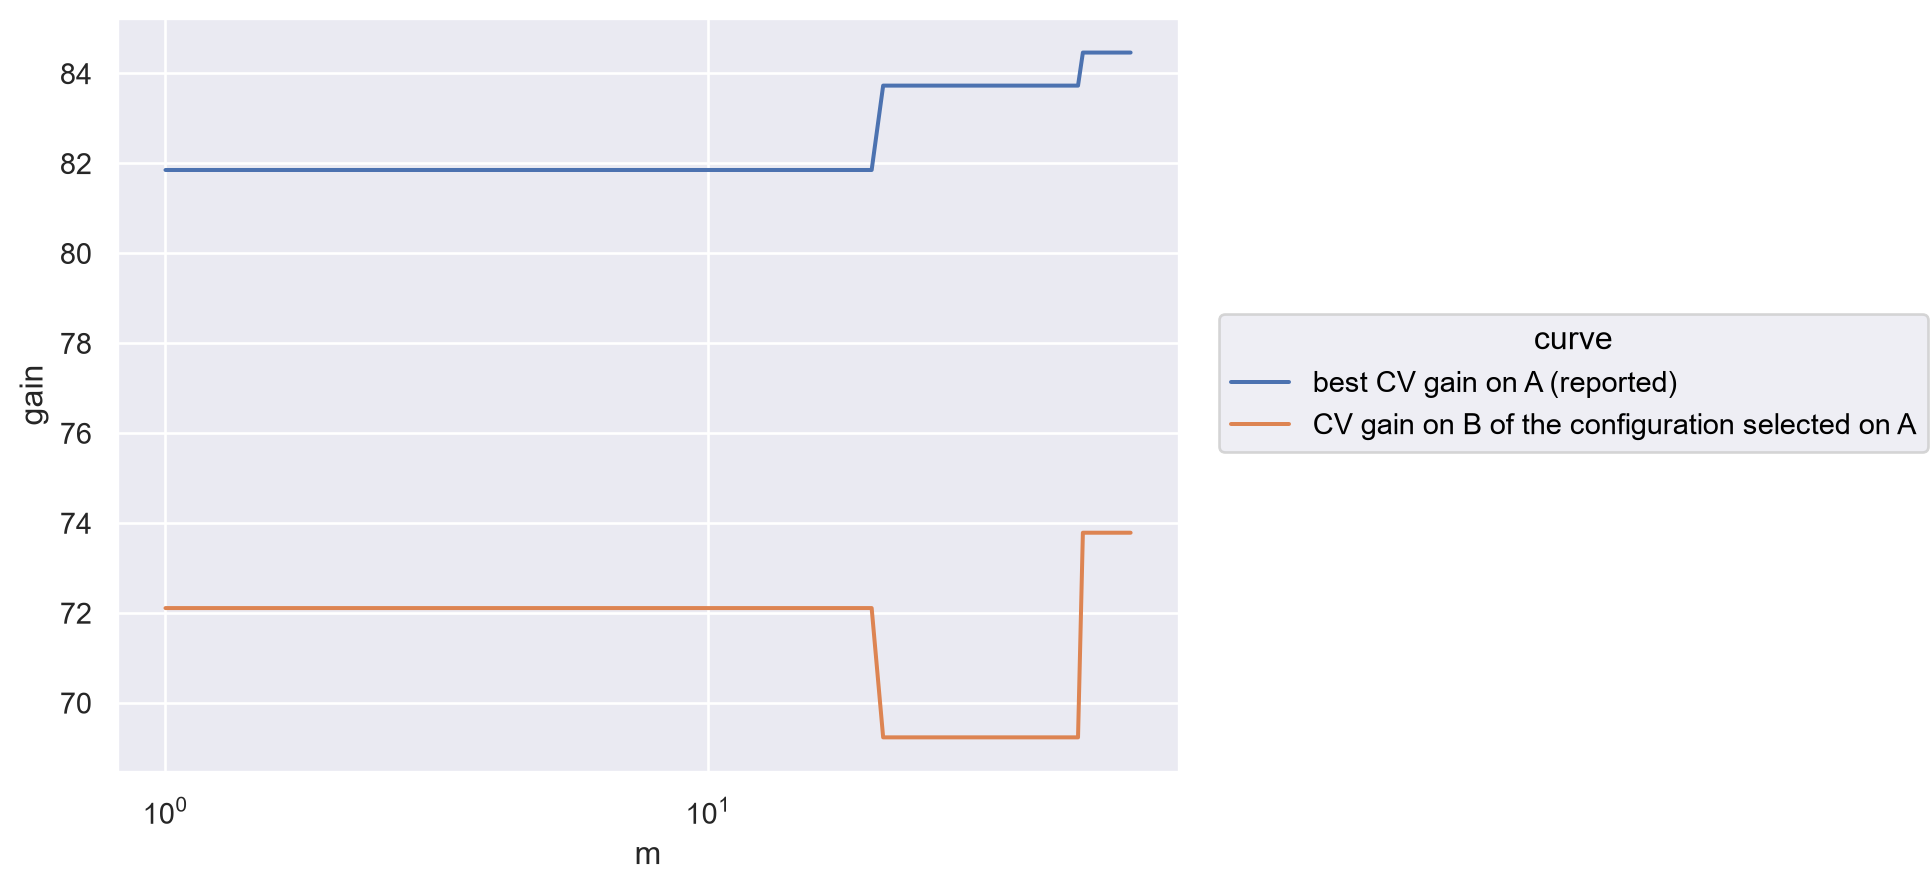

In [23]:
from sklearn.model_selection import ParameterSampler
X_small, _, y_small, _ = train_test_split(X_train, y_train, train_size=400, random_state=0, stratify=y_train)
configurations = list(ParameterSampler(distributions, n_iter=60, random_state=1))
folds = {'A': StratifiedKFold(n_splits=3, shuffle=True, random_state=10), 'B': StratifiedKFold(n_splits=3, shuffle=True, random_state=11)}
trials = pl.DataFrame([{f'CV gain {name}': cross_val_score(clone(pipeline_hgb).set_params(**params), X_small, y_small, cv=cv,
                                                             scoring=cost_scorer_from_proba,
                                                             params={'LoanAmount': X_small['LoanAmount']}).mean()
                        for name, cv in folds.items()} for params in configurations])
selected = [int(trials['CV gain A'][:m].arg_max()) for m in range(1, len(trials) + 1)]
curves = pl.DataFrame({'m': range(1, len(trials) + 1),
                       'best CV gain on A (reported)': trials['CV gain A'].to_numpy()[selected],
                       'CV gain on B of the configuration selected on A': trials['CV gain B'].to_numpy()[selected]})
so.Plot(curves.unpivot(index='m', variable_name='curve', value_name='gain'), x='m', y='gain', color='curve').add(so.Line()).scale(x='log')

In [24]:
curves.filter(pl.col('m').is_in([1, 5, 10, 30, 60])).with_columns(
    (pl.col('best CV gain on A (reported)') - pl.col('CV gain on B of the configuration selected on A')).alias('optimism'))

m,best CV gain on A (reported),CV gain on B of the configuration selected on A,optimism
i64,f64,f64,f64
1,81.853409,72.109734,9.743675
5,81.853409,72.109734,9.743675
10,81.853409,72.109734,9.743675
30,83.7301,69.234329,14.495771
60,84.465305,73.785767,10.679538


**Conclusion** The best gain on A rises from $81.9$ to $84.5$ over the search, while the selected configurations score between $69$ and $74$ on B. Even the first configuration can score differently across shuffles. This experiment measures split sensitivity. Isolating selection optimism requires disjoint evaluation data, for example an outer validation fold.

---

## 4. Validation of a time series forecast

We forecast the monthly CO$_2$ concentration at Mauna Loa (1958–2001, bundled with `statsmodels`) **one year ahead**: at the end of month $t$, we want $y_{t+12}$. Only the values up to time $t$ can be used, so the features of the target $y_s$ can only use $y_{s-12}, y_{s-13}, \dots$ (the *lags* larger than the horizon), the calendar (month) and the time.

The last $10$ years (1992–2001) are kept as a test period. Freeze the fit in December 1990, before the January 1991 origin of the first forecast.

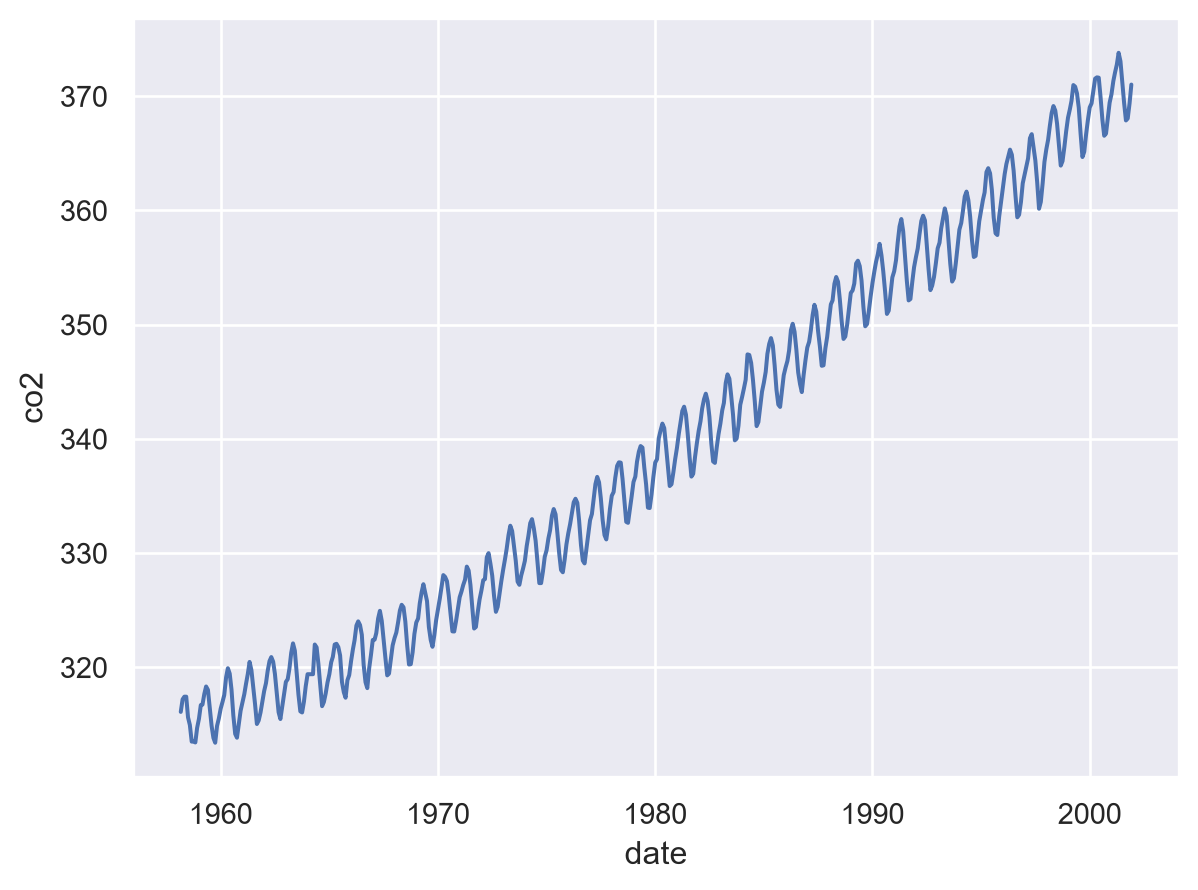

In [25]:
import statsmodels.api as sm
co2 = sm.datasets.co2.load_pandas().data['co2'].resample('MS').mean().ffill()
co2 = pl.DataFrame({'date': co2.index.to_numpy(), 'co2': co2.to_numpy()})
H = 12  # forecast horizon (months)
co2_features = (co2.with_columns(pl.col('date').dt.month().alias('month'),
                                 ((pl.col('date').dt.year() - 1958) + (pl.col('date').dt.month() - 1) / 12).alias('time'),
                                 *[pl.col('co2').shift(lag).alias(f'lag_{lag}') for lag in range(H, H + 13)])
                .with_columns(*[f(2 * np.pi * k * pl.col('month') / 12).alias(f'{f.__name__}_{k}')
                                for k in (1, 2) for f in (np.sin, np.cos)])
                .drop_nulls())
train_ts = co2_features.filter(pl.col('date').dt.year() < 1991)
test_ts = co2_features.filter(pl.col('date').dt.year() >= 1992)
features = ['time', 'sin_1', 'cos_1', 'sin_2', 'cos_2'] + [f'lag_{lag}' for lag in range(H, H + 13)]
so.Plot(co2, x='date', y='co2').add(so.Line())

**Question** The *seasonal naive* forecast predicts $y_{t+12}$ by $y_t$, i.e. $\hat{y}_s = y_{s-12}$ (`lag_12`). Compute its mean absolute error (MAE) on the test period. Then fit a ridge regression and a `HistGradientBoostingRegressor` on the `features`, and compute their test MAE.

**Answer**

In [26]:
from sklearn.linear_model import RidgeCV
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error
models_ts = {'ridge': Pipeline([('scaler', StandardScaler()), ('model', RidgeCV(alphas=np.logspace(-3, 3, 13)))]),
             'gradient boosting': HistGradientBoostingRegressor(random_state=0)}
test_mae = {'seasonal naive': mean_absolute_error(test_ts['co2'], test_ts['lag_12'])}
for name, model in models_ts.items():
  model.fit(train_ts[features], train_ts['co2'])
  test_mae[name] = mean_absolute_error(test_ts['co2'], model.predict(test_ts[features]))
test_mae

{'seasonal naive': 1.5303333333333327,
 'ridge': 0.6615587633291853,
 'gradient boosting': 9.007799972137109}

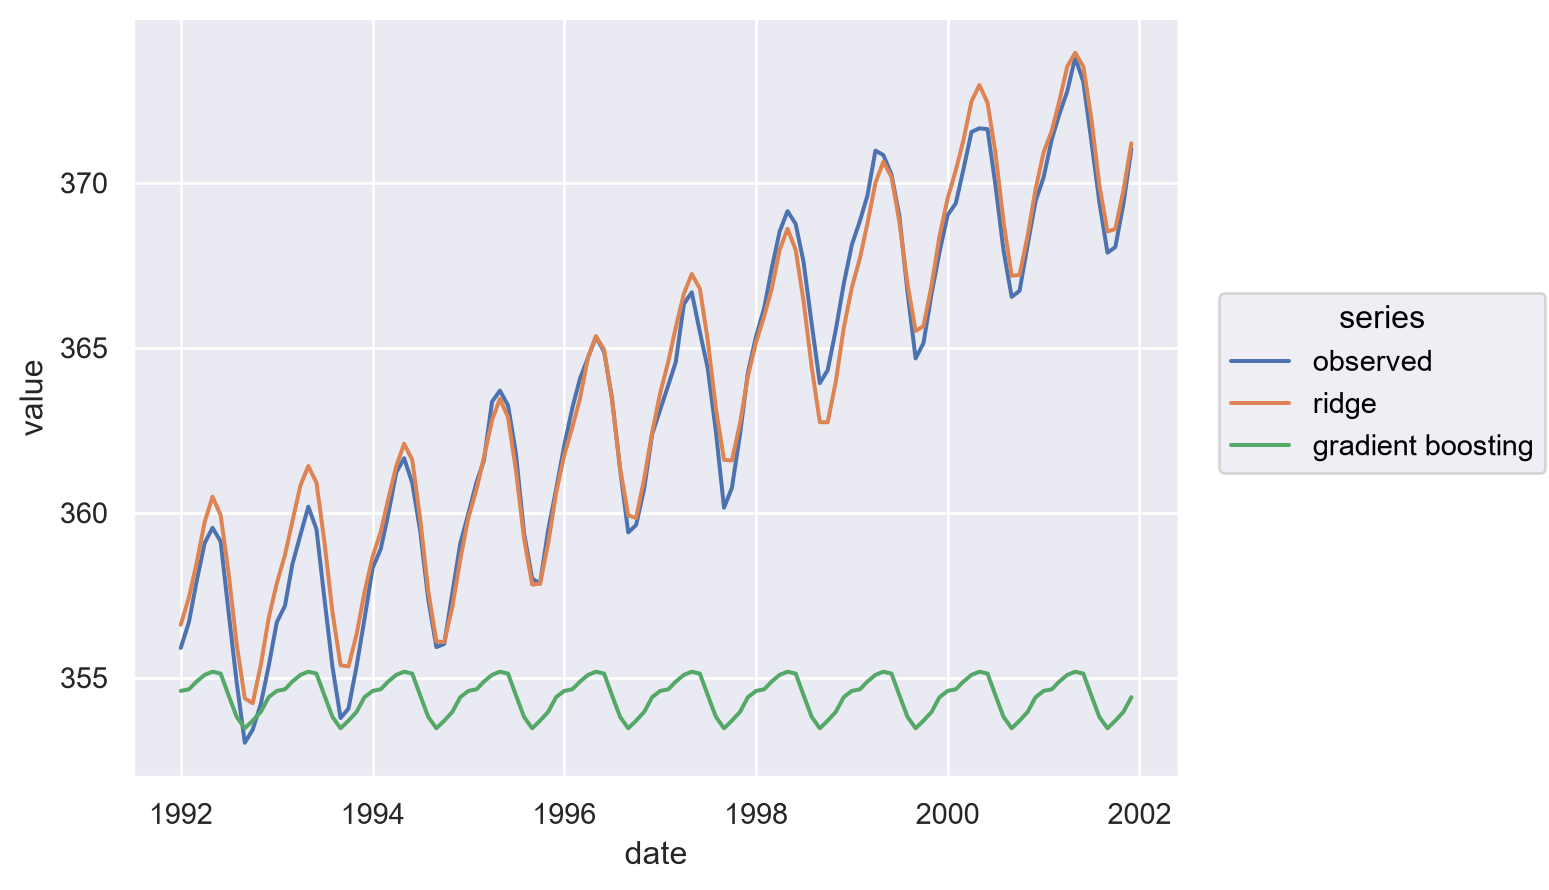

In [27]:
predictions = pl.concat([test_ts.select('date', pl.col('co2').alias('value'), pl.lit('observed').alias('series'))]
                        + [test_ts.select('date', pl.Series('value', model.predict(test_ts[features])), pl.lit(name).alias('series'))
                           for name, model in models_ts.items()])
so.Plot(predictions, x='date', y='value', color='series').add(so.Line())

**Conclusion** Across the 120 test months the seasonal naive forecast has MAE $1.53$ ppm. Ridge reduces this to $0.66$ ppm. Boosting on levels gives $9.01$ ppm because the trees cannot extrapolate the long-run trend beyond the training range.

---

**Question** *Predict before you run.* We want to choose between these models with the training period only. Compare the MAE estimated by a shuffled $5$-fold cross validation, by `TimeSeriesSplit(n_splits=5, test_size=24, gap=H)` (each validation block comes after its training part, with a gap of at least the horizon), and the test MAE. Which estimation is reliable?

**Answer**

In [28]:
from sklearn.model_selection import KFold, TimeSeriesSplit, cross_val_score
splitters = {'shuffled 5-fold': KFold(n_splits=5, shuffle=True, random_state=0),
             'time series split (gap = H)': TimeSeriesSplit(n_splits=5, test_size=24, gap=H)}
cv_mae = [{'model': name, 'estimation': split_name,
           'MAE': -cross_val_score(model, train_ts[features], train_ts['co2'], cv=splitter,
                                   scoring='neg_mean_absolute_error').mean()}
          for name, model in models_ts.items() for split_name, splitter in splitters.items()]
cv_mae += [{'model': name, 'estimation': 'test period', 'MAE': test_mae[name]} for name in models_ts]
pl.DataFrame(cv_mae).pivot(index='model', on='estimation', values='MAE')

model,shuffled 5-fold,time series split (gap = H),test period
str,f64,f64,f64
"""ridge""",0.443092,0.416968,0.661559
"""gradient boosting""",0.502082,3.426197,9.0078


**Conclusion** Shuffled CV gives MAEs of $0.44$ ppm for ridge and $0.50$ for boosting. Forward CV with a 12-month gap gives $0.42$ and $3.43$, respectively. Both splits rank ridge first, but shuffled CV substantially understates the cost of extrapolation for boosting. Even the forward blocks are shorter than the ten-year test period.

---

**Question** Trees cannot extrapolate: the gradient boosting predicts values in the range of its training targets. *Stationarize* the series by forecasting the seasonal difference $y_{t+12} - y_t$ (i.e. predict `co2 - lag_12` and add `lag_12` back), and compare the test MAE of both models.

**Answer**

In [29]:
target_diff = train_ts['co2'] - train_ts['lag_12']
for name, model in models_ts.items():
  model.fit(train_ts[features], target_diff)
  test_mae[name + ' (seasonal difference)'] = mean_absolute_error(test_ts['co2'], test_ts['lag_12'] + model.predict(test_ts[features]))
pl.DataFrame({'model': list(test_mae), 'test MAE': list(test_mae.values())}).sort('test MAE')

model,test MAE
str,f64
"""ridge (seasonal difference)""",0.622245
"""gradient boosting (seasonal di…",0.639772
"""ridge""",0.661559
"""seasonal naive""",1.530333
"""gradient boosting""",9.0078


**Conclusion** Predicting the seasonal difference reduces boosting MAE from $9.01$ to $0.64$ ppm and ridge MAE from $0.66$ to $0.62$. Adding the latest available seasonal level back to the prediction lets both models track the rising series.

---

## About this lab

**Use of AI.** Artificial intelligence tools have been used to revise the content of this lab. The main contributor takes full responsibility for this content.

**License.** The texts of this lab are under the [Creative Commons Attribution-ShareAlike 4.0](https://creativecommons.org/licenses/by-sa/4.0/) license (CC BY-SA 4.0), and its code under the [MIT](https://opensource.org/license/mit) license; the datasets keep their own licenses. Main contributor: E. Le Pennec. Contributors: S. Boucheron, A. Dieuleveut, A.K. Fermin, S. Gadat, S. Gaiffas, B. Goujaud, A. Guilloux, Ch. Keribin, Th. Klein, E. Matzner, J. Read, M. Sangnier, E. Scornet.